# Yash: historical inverse PINN study
Real Hudson's Bay Company pelt indices from Advay's Stan compilation, **not synthetic data**.
Training: 1900-1915. Frozen evaluation: 1916-1920. Counts are thousands of pelts, not animal censuses.

This notebook includes the complete model and inverse-PINN training implementations, explains the protocol,
and independently reconstructs the saved forecasts. Default execution audits and displays completed runs;
it does **not** pretend to retrain them. Reproduction commands below create new output directories.
The old synthetic notebook remains the separate controlled recovery study.

In [1]:
import sys, json, hashlib, csv
from pathlib import Path
import numpy as np
import torch
from IPython.display import display, Image, HTML
from html import escape
def show_table(rows):
    names=list(rows[0])
    header='<tr>'+''.join('<th>'+escape(str(n))+'</th>' for n in names)+'</tr>'
    body=''.join('<tr>'+''.join('<td>'+escape(str(row[n]))+'</td>' for n in names)+'</tr>' for row in rows)
    display(HTML('<table>'+header+body+'</table>'))
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
assert (ROOT / 'src/lynx_hare/model.py').exists(), 'Run in the repository root or notebooks/'
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))
BASE = ROOT / 'results/historical'
config = json.loads((ROOT / 'configs/historical.json').read_text())
show_table([{'parameter':n,'initial_guess':config['initial_guess'][n],'bounds':config['bounds'][n]} for n in config['initial_guess']])

parameter,initial_guess,bounds
r,0.8,"[0.05, 3.0]"
K,150.0,"[20.0, 500.0]"
a,2.0,"[0.05, 10.0]"
b,30.0,"[0.5, 300.0]"
e,0.6,"[0.02, 5.0]"
m,0.6,"[0.05, 3.0]"


## Complete scientific implementation
The following executable cells mirror the canonical modules. Relative imports are rewritten to their
package names so the cells run in Jupyter. The packaged modules and runner remain the canonical route
for batch reproduction; all source hashes are recorded in the notebook metadata and run manifests.

The model uses logistic hare growth and Holling-II predation. The data contract validates positive,
ordered observations and computes scales from training rows only. Positive states, bounded parameters,
automatic-differentiation residuals, deterministic Adam/L-BFGS training and optional fitted initial
states are implemented below. No generating truth enters historical fitting.

In [2]:
# Complete implementation: src/lynx_hare/model.py
"""Shared dimensional model and RK45 solver, provisional until team agreement."""
from dataclasses import dataclass, asdict
import numpy as np
from scipy.integrate import solve_ivp

NAMES = ("r", "K", "a", "b", "e", "m")


@dataclass(frozen=True)
class Parameters:
    r: float
    K: float
    a: float
    b: float
    e: float
    m: float

    def __post_init__(self):
        if not all(np.isfinite(v) and v > 0 for v in asdict(self).values()):
            raise ValueError("Every model parameter must be finite and positive")

    def to_dict(self):
        return asdict(self)


def rhs(t, state, p):
    """H' = rH(1-H/K)-aHP/(b+H); P' = eaHP/(b+H)-mP."""
    H, P = state
    consumption = p.a * H * P / (p.b + H)
    return np.array([p.r * H * (1 - H / p.K) - consumption,
                     p.e * consumption - p.m * P])


def rhs_torch(state, p):
    """Same equations, batch shape (N, 2), preserving the autograd graph."""
    import torch
    H, P = state[:, :1], state[:, 1:]
    consumption = p["a"] * H * P / (p["b"] + H)
    return torch.cat((p["r"] * H * (1 - H / p["K"]) - consumption,
                      p["e"] * consumption - p["m"] * P), dim=1)


def solve(times, initial_state, p, rtol=1e-8, atol=1e-10, max_step=0.1):
    """State at strictly increasing times; initial_state belongs to times[0]."""
    times = np.asarray(times, dtype=float)
    y0 = np.asarray(initial_state, dtype=float)
    if times.ndim != 1 or times.size == 0 or not np.isfinite(times).all():
        raise ValueError("times must be a nonempty finite 1D array")
    if np.any(np.diff(times) <= 0) or y0.shape != (2,) or not np.isfinite(y0).all() or np.any(y0 < 0):
        raise ValueError("times must increase; initial_state must contain two nonnegative values")
    if times.size == 1:
        return y0[None, :].copy()
    result = solve_ivp(lambda t, y: rhs(t, y, p), (times[0], times[-1]), y0,
                       t_eval=times, method="RK45", rtol=rtol, atol=atol, max_step=max_step)
    if not result.success or result.y.shape[1] != len(times):
        raise RuntimeError(f"ODE integration failed: {result.message}")
    states = result.y.T
    if not np.isfinite(states).all() or np.min(states) < -100 * atol:
        raise RuntimeError("ODE returned invalid or negative states")
    return states

In [3]:
# Complete implementation: src/lynx_hare/data.py
"""Validated training contract and independently generated synthetic observations."""
from dataclasses import dataclass
from pathlib import Path
import csv
import numpy as np
from lynx_hare.model import Parameters, solve


@dataclass
class TrainingData:
    years: np.ndarray
    observations: np.ndarray
    time_origin: float

    def __post_init__(self):
        self.years = np.asarray(self.years, dtype=float)
        self.observations = np.asarray(self.observations, dtype=float)
        if (self.years.ndim != 1 or len(self.years) < 2
                or self.observations.shape != (len(self.years), 2)
                or not np.isfinite(self.years).all()
                or not np.isfinite(self.observations).all()
                or np.any(np.diff(self.years) <= 0)
                or np.any(self.observations <= 0)
                or not np.isfinite(self.time_origin)
                or self.years[0] != self.time_origin):
            raise ValueError("Training data require increasing years and positive finite Hare/Lynx observations, starting at time_origin")

    @property
    def times(self):
        return self.years - self.time_origin

    @property
    def scale(self):
        # This method has no access to test observations or generating parameters.
        return self.observations.max(axis=0)

    @property
    def initial_state(self):
        return self.observations[0].copy()


def write_csv(path, columns, values):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(columns)
        writer.writerows(values)


def read_training(path, time_origin=1900, train_end=1915):
    with Path(path).open(newline="", encoding="utf-8-sig") as f:
        rows = list(csv.DictReader(f))
    values = np.array([[float(r[k]) for k in ("Year", "Hare", "Lynx")] for r in rows])
    values = values[values[:, 0] <= train_end]
    return TrainingData(values[:, 0], values[:, 1:], time_origin)


def synthetic(config, times, noise_fraction=None, seed=None):
    """Noise is multiplicative Gaussian with exact controlled initial condition.

    In this synthetic experiment the initial state is treated as measured exactly.
    This is an explicit experimental assumption, not a claim about pelt data.
    """
    noise = config["noise_fraction"] if noise_fraction is None else noise_fraction
    if noise < 0:
        raise ValueError("noise_fraction cannot be negative")
    states = solve(times, config["initial_state"], Parameters(**config["truth"]), **config["solver"])
    rng = np.random.default_rng(config["data_seed"] if seed is None else seed)
    observed = states * (1 + noise * rng.normal(size=states.shape))
    observed = np.maximum(observed, 1e-8)
    observed[0] = states[0]
    return states, observed

In [4]:
# Complete implementation: src/lynx_hare/pinn.py
"""Inverse PINN trained only on a TrainingData object and fixed configuration."""
import copy
import random
import time
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from lynx_hare.model import NAMES, Parameters, rhs_torch

DTYPE = torch.float64


class InversePINN(nn.Module):
    def __init__(self, duration, scale, guess, bounds, trainable, width=48, depth=3):
        super().__init__()
        if duration <= 0 or not set(trainable).issubset(NAMES) or len(set(trainable)) != len(trainable):
            raise ValueError("Invalid duration or trainable parameter names")
        self.duration = float(duration)
        self.register_buffer("scale", torch.as_tensor(scale, dtype=DTYPE))
        self.fixed = {k: float(v) for k, v in guess.items() if k not in trainable}
        self.bounds = bounds
        self.raw = nn.ParameterDict()
        for k in trainable:
            lo, hi = bounds[k]
            if not 0 < lo < guess[k] < hi:
                raise ValueError(f"Initial guess for {k} must lie strictly within positive bounds")
            q = (guess[k] - lo) / (hi - lo)
            self.raw[k] = nn.Parameter(torch.tensor(np.log(q / (1 - q)), dtype=DTYPE))
        layers = [nn.Linear(1, width), nn.Tanh()]
        for _ in range(depth - 1):
            layers.extend((nn.Linear(width, width), nn.Tanh()))
        layers.append(nn.Linear(width, 2))
        self.network = nn.Sequential(*layers).to(dtype=DTYPE)
        for layer in self.network:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_normal_(layer.weight)
                nn.init.zeros_(layer.bias)

    def parameter_values(self):
        values = dict(self.fixed)
        for k, raw in self.raw.items():
            lo, hi = self.bounds[k]
            values[k] = lo + (hi - lo) * torch.sigmoid(raw)
        return values

    def inferred(self):
        return Parameters(**{k: float(v.detach()) if isinstance(v, torch.Tensor) else float(v)
                             for k, v in self.parameter_values().items()})

    def forward(self, times):
        # The network is defined on scaled time [-1, 1]. Output positivity is strict.
        return F.softplus(self.network(2 * times / self.duration - 1)) + 1e-10

    def residuals(self, times):
        times = times.detach().clone().requires_grad_(True)
        normalized = self(times)
        derivatives = torch.cat([
            torch.autograd.grad(normalized[:, j:j+1], times,
                                torch.ones_like(normalized[:, j:j+1]), create_graph=True)[0]
            for j in range(2)], dim=1)
        return derivatives - rhs_torch(normalized * self.scale, self.parameter_values()) / self.scale


def loss_parts(model, times, observations, collocation, initial):
    data = ((model(times) - observations / model.scale) ** 2).mean()
    residual = model.residuals(collocation)
    physics_hare = residual[:, 0].square().mean()
    physics_lynx = residual[:, 1].square().mean()
    ic = ((model(torch.zeros((1, 1), dtype=DTYPE)) - initial / model.scale) ** 2).mean()
    return {"data": data, "physics": (physics_hare + physics_lynx) / 2,
            "physics_hare": physics_hare, "physics_lynx": physics_lynx, "ic": ic}


def fit_pinn(data, config, seed, training_overrides=None, initial_factor=1.0, trainable=None):
    """No truth, held-out observations, or held-out metrics enter optimization."""
    settings = {**config["training"], **(training_overrides or {})}
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(settings["threads"])
    torch.use_deterministic_algorithms(True)
    names = config["trainable"] if trainable is None else trainable
    guess = dict(config["initial_guess"])
    for k in names:
        lo, hi = config["bounds"][k]
        guess[k] = float(np.clip(guess[k] * initial_factor, lo + 1e-4, hi - 1e-4))
    model = InversePINN(data.times[-1], data.scale, guess, config["bounds"], names,
                        settings["width"], settings["depth"])
    times = torch.as_tensor(data.times[:, None], dtype=DTYPE)
    observed = torch.as_tensor(data.observations, dtype=DTYPE)
    initial = torch.as_tensor(data.initial_state, dtype=DTYPE)
    collocation = torch.linspace(0, data.times[-1], settings["collocation_points"], dtype=DTYPE)[:, None]
    history, best_state = [], None
    best_loss, stale, best_iteration = float("inf"), 0, -1
    start = time.perf_counter()

    def total(parts):
        return (settings["data_weight"] * parts["data"] + settings["physics_weight"] * parts["physics"]
                + settings["ic_weight"] * parts["ic"])

    def record(stage, step):
        nonlocal best_state, best_loss, stale, best_iteration
        parts = loss_parts(model, times, observed, collocation, initial)
        score = float(total(parts).detach())
        if not np.isfinite(score):
            raise RuntimeError("Nonfinite PINN training objective")
        history.append({"stage": stage, "step": step, "total": score,
                        **{k: float(v.detach()) for k, v in parts.items()}})
        improved_materially = score < best_loss - settings["min_delta"]
        stale = 0 if improved_materially else stale + 1
        if score < best_loss:
            best_loss, best_state, best_iteration = score, copy.deepcopy(model.state_dict()), step
        return score

    optimizer = torch.optim.Adam(model.parameters(), lr=settings["learning_rate"])
    # Warmup fits states before physics is introduced. No parameters are inferred in warmup.
    for _ in range(settings["warmup_steps"]):
        optimizer.zero_grad()
        warm = ((model(times) - observed / model.scale) ** 2).mean()
        warm = warm + settings["ic_weight"] * ((model(times[:1]) - initial / model.scale) ** 2).mean()
        warm.backward()
        optimizer.step()
    record("joint_adam", 0)
    adam_stop = "maximum_steps"
    for step in range(1, settings["adam_steps"] + 1):
        optimizer.zero_grad()
        objective = total(loss_parts(model, times, observed, collocation, initial))
        if not torch.isfinite(objective):
            raise RuntimeError("Nonfinite PINN loss")
        objective.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), settings["gradient_clip"])
        optimizer.step()
        if step % settings["log_every"] == 0 or step == settings["adam_steps"]:
            record("joint_adam", step)
            if stale >= settings["patience"]:
                adam_stop = "training_plateau"
                break
    model.load_state_dict(best_state)
    closure_evaluations = 0
    optimizer2 = torch.optim.LBFGS(model.parameters(), max_iter=settings["lbfgs_steps"],
                                  line_search_fn="strong_wolfe", tolerance_grad=1e-10,
                                  tolerance_change=1e-12, history_size=50)

    def closure():
        nonlocal closure_evaluations
        optimizer2.zero_grad()
        objective = total(loss_parts(model, times, observed, collocation, initial))
        if not torch.isfinite(objective):
            raise RuntimeError("Nonfinite L-BFGS loss")
        objective.backward()
        closure_evaluations += 1
        if closure_evaluations % 25 == 0:
            record("lbfgs", settings["adam_steps"] + closure_evaluations)
        return objective

    if settings["lbfgs_steps"]:
        optimizer2.step(closure)
        record("lbfgs_final", settings["adam_steps"] + closure_evaluations)
    model.load_state_dict(best_state)
    audit = {"seed": seed, "settings": settings, "trainable": names, "initial_guess": guess,
             "fixed": model.fixed, "scale": data.scale.tolist(), "train_years": data.years.tolist(),
             "training_objective": best_loss, "best_iteration": best_iteration,
             "adam_stop": adam_stop, "lbfgs_iterations": optimizer2.state.get(next(iter(model.parameters())), {}).get("n_iter", 0),
             "lbfgs_closure_evaluations": closure_evaluations,
             "elapsed_seconds": time.perf_counter() - start,
             "selection_rule": "minimum weighted training loss; held-out data never used"}
    return model, history, audit

In [5]:
# Complete implementation: src/lynx_hare/historical_pinn.py
"""Historical fitting extensions; synthetic experiment sources remain frozen.

Only a TrainingData object enters optimization. Historical coefficients are effective
coefficients in the observation units, with bounds supplied by the common team config.
"""
import copy
import random
import time

import numpy as np
import torch
from torch import nn

from lynx_hare.model import NAMES
from lynx_hare.pinn import DTYPE, InversePINN


def validate_config(config):
    """Require explicit historical choices instead of borrowing synthetic constants."""
    if config.get("kind") != "historical" or "truth" in config:
        raise ValueError("Provide a historical config without generating truth")
    names = config.get("trainable", [])
    if not names or len(set(names)) != len(names) or not set(names) <= set(NAMES):
        raise ValueError("Declare distinct trainable model parameters")
    guesses, bounds = config.get("initial_guess"), config.get("bounds")
    if not isinstance(guesses, dict) or set(guesses) != set(NAMES):
        raise ValueError("Please supply initial_guess for all six parameters")
    if not isinstance(bounds, dict):
        raise ValueError("Please supply common positive parameter bounds")
    for name in NAMES:
        if not np.isfinite(guesses[name]) or guesses[name] <= 0:
            raise ValueError(f"Invalid initial/fixed value for {name}")
        if name in names:
            lo, hi = bounds[name]
            if not np.isfinite([lo, hi]).all() or not 0 < lo < guesses[name] < hi:
                raise ValueError(f"Require positive bounds containing the guess for {name}")
    if set(config.get("solver", {})) != {"rtol", "atol", "max_step"}:
        raise ValueError("Declare shared rtol, atol and max_step")
    if any(not np.isfinite(v) or v <= 0 for v in config["solver"].values()):
        raise ValueError("Solver settings must be finite and positive")
    for key in ("start_year", "train_end_year", "forecast_end_year", "training", "seeds"):
        if key not in config:
            raise ValueError(f"Missing {key}")
    if not config["start_year"] < config["train_end_year"] < config["forecast_end_year"]:
        raise ValueError("Require training years before forecast years")
    if not config["seeds"] or len(set(config["seeds"])) != len(config["seeds"]):
        raise ValueError("Declare distinct optimization seeds")
    if any(not isinstance(seed, int) or seed < 0 for seed in config["seeds"]):
        raise ValueError("Seeds must be nonnegative integers")
    settings = config["training"]
    for key in ("width", "depth", "collocation_points", "log_every", "patience", "threads"):
        if not isinstance(settings.get(key), int) or settings[key] < 1:
            raise ValueError(f"Require a positive integer {key}")
    if settings["collocation_points"] < 2:
        raise ValueError("Use at least two collocation points")
    for key in ("warmup_steps", "adam_steps", "lbfgs_steps"):
        if not isinstance(settings.get(key), int) or settings[key] < 0:
            raise ValueError(f"Require nonnegative integer {key}")
    for key in ("learning_rate", "data_weight", "physics_weight", "ic_weight", "gradient_clip", "min_delta"):
        value = settings.get(key)
        if value is None or not np.isfinite(value) or value < 0 or (key != "min_delta" and value == 0):
            raise ValueError(f"Invalid {key}")


class HistoricalPINN(InversePINN):
    def __init__(self, data, config, fit_initial=False):
        settings = config["training"]
        super().__init__(data.times[-1], data.scale, config["initial_guess"],
                         config["bounds"], config["trainable"],
                         settings["width"], settings["depth"])
        self.register_buffer("observed_initial", torch.as_tensor(data.initial_state, dtype=DTYPE))
        self.fit_initial = bool(fit_initial)
        if fit_initial:
            # Midpoint of [0.5*y0, 1.5*y0] is the observed initial state.
            self.raw_initial = nn.Parameter(torch.zeros(2, dtype=DTYPE))

    def initial_values(self):
        if self.fit_initial:
            return self.observed_initial * (0.5 + torch.sigmoid(self.raw_initial))
        return self.observed_initial


def observation_loss(predicted, observed, scale, error_model):
    if error_model == "additive":
        return ((predicted - observed) / scale).square().mean()
    if error_model == "log":
        return (torch.log(predicted) - torch.log(observed)).square().mean()
    raise ValueError("error_model must be additive or log")


def loss_parts(model, times, observed, collocation, error_model="additive"):
    data_loss = observation_loss(model(times) * model.scale, observed, model.scale, error_model)
    residual = model.residuals(collocation)
    initial = model.initial_values()
    ic = ((model(times[:1]) - initial / model.scale) ** 2).mean()
    return {"data": data_loss, "physics": residual.square().mean(), "ic": ic,
            "physics_hare": residual[:, 0].square().mean(),
            "physics_lynx": residual[:, 1].square().mean()}


def fit_historical(data, config, seed, error_model="additive", fit_initial=False):
    """Fit a frozen training split; no test path or test observations are accepted."""
    validate_config(config)
    if data.years.tolist() != list(range(config["start_year"], config["train_end_year"] + 1)):
        raise ValueError("TrainingData must contain the complete declared annual training split")
    if error_model not in ("additive", "log"):
        raise ValueError("error_model must be additive or log")
    s = config["training"]
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(s["threads"])
    torch.use_deterministic_algorithms(True)
    model = HistoricalPINN(data, config, fit_initial)
    times = torch.tensor(data.times[:, None], dtype=DTYPE)
    observed = torch.tensor(data.observations, dtype=DTYPE)
    collocation = torch.linspace(0, data.times[-1], s["collocation_points"], dtype=DTYPE)[:, None]
    start = time.perf_counter()
    history, best_state = [], None
    best_loss, stale, best_iteration = float("inf"), 0, -1

    def total(parts):
        return sum(s[f"{key}_weight"] * parts[key] for key in ("data", "physics", "ic"))

    def record(stage, step):
        nonlocal best_loss, best_state, stale, best_iteration
        parts = loss_parts(model, times, observed, collocation, error_model)
        score = float(total(parts).detach())
        if not np.isfinite(score):
            raise RuntimeError("Nonfinite historical training loss")
        history.append({"stage": stage, "step": step, "total": score,
                        **{k: float(v.detach()) for k, v in parts.items()}})
        stale = 0 if score < best_loss - s["min_delta"] else stale + 1
        if score < best_loss:
            best_loss, best_state, best_iteration = score, copy.deepcopy(model.state_dict()), step
        return score

    optimizer = torch.optim.Adam(model.parameters(), lr=s["learning_rate"])
    for _ in range(s["warmup_steps"]):
        optimizer.zero_grad()
        data_loss = observation_loss(model(times) * model.scale, observed, model.scale, error_model)
        ic = ((model(times[:1]) - model.initial_values() / model.scale) ** 2).mean()
        warmup = s["data_weight"] * data_loss + s["ic_weight"] * ic
        warmup.backward()
        optimizer.step()
    record("joint_adam", 0)
    adam_stop = "maximum_steps"
    for step in range(1, s["adam_steps"] + 1):
        optimizer.zero_grad()
        objective = total(loss_parts(model, times, observed, collocation, error_model))
        if not torch.isfinite(objective):
            raise RuntimeError("Nonfinite historical Adam loss")
        objective.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), s["gradient_clip"])
        optimizer.step()
        if step % s["log_every"] == 0 or step == s["adam_steps"]:
            record("joint_adam", step)
            if stale >= s["patience"]:
                adam_stop = "training_plateau"
                break
    model.load_state_dict(best_state)
    closure_evaluations = 0
    lbfgs = torch.optim.LBFGS(model.parameters(), max_iter=s["lbfgs_steps"],
                             line_search_fn="strong_wolfe", tolerance_grad=1e-10,
                             tolerance_change=1e-12, history_size=50)

    def closure():
        nonlocal closure_evaluations
        lbfgs.zero_grad()
        objective = total(loss_parts(model, times, observed, collocation, error_model))
        if not torch.isfinite(objective):
            raise RuntimeError("Nonfinite historical L-BFGS loss")
        objective.backward()
        closure_evaluations += 1
        if closure_evaluations % 25 == 0:
            record("lbfgs", s["adam_steps"] + closure_evaluations)
        return objective

    if s["lbfgs_steps"]:
        lbfgs.step(closure)
        record("lbfgs_final", s["adam_steps"] + closure_evaluations)
    model.load_state_dict(best_state)
    with torch.no_grad():
        network_initial = (model(times[:1]) * model.scale).numpy()[0]
        ode_initial = model.initial_values().numpy()
    audit = {"seed": int(seed), "settings": dict(s), "trainable": config["trainable"],
             "fixed": model.fixed, "initial_guess": config["initial_guess"],
             "scale": data.scale.tolist(), "train_years": data.years.tolist(),
             "error_model": error_model, "fit_initial": fit_initial,
             "initial_bounds_factors": [0.5, 1.5] if fit_initial else None,
             "observed_initial": data.initial_state.tolist(), "ode_initial": ode_initial.tolist(),
             "network_initial": network_initial.tolist(),
             "network_minus_ode_initial": (network_initial - ode_initial).tolist(),
             "network_minus_observed_initial": (network_initial - data.initial_state).tolist(),
             "training_objective": best_loss, "best_iteration": best_iteration,
             "adam_stop": adam_stop, "lbfgs_closure_evaluations": closure_evaluations,
             "elapsed_seconds": time.perf_counter() - start,
             "selection_rule": "minimum weighted training loss within each variant; no held-out scores"}
    return model, history, audit

## Frozen data and loss
The primary residual is `(prediction-observation)/training_max`, with one equal contribution per species.
The physics residual differentiates normalized states with respect to physical time, retaining both time
and state scaling. Weights are data=1, physics=10, IC=10. The network has 3 x 48 tanh units; outputs use
softplus and all six parameters use positive sigmoid bounds. The primary ODE initial state is (30,4).
The PINN's initial-state constraint is soft, and its discrepancy is explicitly reported.

Seeds 17,29,43 are selected by weighted **training** loss within each variant. Log errors and fitted
initial states are separate declared sensitivities. Wider bounds and physics weight 100 are retained
as sensitivity results, not promoted after scoring. The local benchmark uses the exact same primary
config; it is an independent check, not a claim that Advay has completed his own fitting task.

In [6]:
from run_historical_pinn import training_split
data, train_path = training_split(ROOT)
validate_config(config)
assert data.years.tolist() == list(range(1900,1916))
show_table([{'species':n,'scale':float(data.scale[i]),'observed_initial':float(data.initial_state[i])} for i,n in enumerate(['Hare','Lynx'])])
from score_historical import frozen
for folder in ['yash_pinn_v1','yash_pinn_wider_v1','yash_pinn_physics100_v1','yash_matching_baseline_v2']:
    assert frozen(BASE/folder)['status'] == 'forecasts_frozen_unscored'
print('All frozen output and scientific-source hashes verified.')

species,scale,observed_initial
Hare,77.4,30.0
Lynx,59.4,4.0


All frozen output and scientific-source hashes verified.


## Independent ODE reconstruction and seed diagnostics
Forecasts use RK45 from 1900 through 1920 with the learned parameters, never neural-network extrapolation.
The code below reconstructs every saved five-year forecast without reading held-out observations.
Local sensitivity condition numbers describe this fitted model only; seed spread is not a confidence interval.

In [7]:
from lynx_hare.model import Parameters as ModelParameters, solve as solve_model
summaries=[]
for dirname in ['yash_pinn_v1','yash_pinn_wider_v1','yash_pinn_physics100_v1']:
    for path in sorted((BASE/dirname/'runs').glob('*/summary.json')):
        s=json.loads(path.read_text())
        predicted=solve_model(np.arange(21), s['audit']['ode_initial'], ModelParameters(**s['parameters']), **config['solver'])
        exported=np.loadtxt(path.parent/'forecast.csv',delimiter=',',skiprows=1)
        np.testing.assert_allclose(predicted[16:],exported[:,1:],rtol=1e-11,atol=1e-11)
        summaries.append({'case':dirname,'run':s['run_id'],**s['parameters'],
                          'sigma':s['diagnostics']['sigma'],'condition':s['diagnostics']['condition_number'],
                          'ODE_training_MSE':s['training_ode_normalized_mse'],
                          'IC_difference':s['audit']['network_minus_observed_initial']})
show_table(summaries)
print('All 13 PINN forecast files independently reconstructed.')

case,run,r,K,a,b,e,m,sigma,condition,ODE_training_MSE,IC_difference
yash_pinn_v1,fitted_initial_seed17,0.5369857392202834,494.3315391000688,8.4267483705291,299.78047611799553,1.2776886710415303,1.0865641827006949,1.3466631084234548,376.32021201792105,0.007397575671543076,"[4.748494882566362, -0.21273733019904562]"
yash_pinn_v1,fitted_initial_seed29,0.5381552010422098,494.75238001877835,8.426021600751403,299.7961783886361,1.2746803572717784,1.083903392139589,1.3477412529835742,378.4647294208746,0.007554467642784173,"[4.776998725351156, -0.1439694727710248]"
yash_pinn_v1,fitted_initial_seed43,0.534185429419636,484.5243524363303,8.37533361295525,299.0496790066312,1.2921963001546541,1.0943713671999775,1.322634777999213,366.5540852873775,0.007108297978537691,"[4.77481864784361, -0.41352318229918517]"
yash_pinn_v1,log_errors_seed17,0.5693255607037517,482.2314889545448,8.099947902699165,285.7523457798198,1.4086939996362906,1.2510623077820082,1.3540878837925454,237.57480586461716,0.03683797954497296,"[0.14308781077327737, 0.03775511719486957]"
yash_pinn_v1,log_errors_seed29,0.5677196050491092,480.208094755309,8.109206367302061,287.32228033361156,1.4167571556077772,1.2536310403118214,1.3424641511292394,238.70758529100775,0.03664816171639651,"[0.14691172120478413, 0.027105604319809906]"
yash_pinn_v1,log_errors_seed43,0.5661685060151416,491.37525627800824,8.301833714423232,295.4530756916458,1.4129289895807018,1.2485027868650747,1.3431444175754768,242.9879566251065,0.03621269717654681,"[0.1458599590206653, 0.03282178237451028]"
yash_pinn_v1,main_seed17,0.6054636470501683,497.6036084434827,9.260547309106517,299.97597885269994,1.0965764328360263,0.9938788576936693,1.3630557174287483,317.4622204217257,0.009814353680621918,"[0.1006049973344254, -0.007232455177729413]"
yash_pinn_v1,main_seed29,0.6053500024895941,496.3887726925364,9.250805360534054,299.9427975014707,1.097921193922284,0.9943007149827313,1.3598108570956315,317.1293144739623,0.00982414706703916,"[0.10036036470651055, -0.006808389810388338]"
yash_pinn_v1,main_seed43,0.6037762601792512,498.720375389894,9.240339855637181,299.99507339569186,1.1016272981598108,0.9970454489674253,1.3658198932860592,318.6781981175164,0.009845020966307724,"[0.09838015703551761, -0.009686621741806345]"
yash_pinn_wider_v1,main_seed17,0.5737460993696418,986.3580878560481,17.196807915747776,599.8806849028679,1.058671770023306,0.9572297740639936,1.479989368056137,593.182639298418,0.009347371363618113,"[0.09810788081879807, -0.006855162558359051]"


All 13 PINN forecast files independently reconstructed.


## Final evaluation and figures
All model choices and forecasts were frozen before evaluation. Scores are RMSE and MAE for each species
in original pelt units, on the same five test years. Primary hare RMSE is slightly better for the PINN,
while primary lynx RMSE is worse. The table contains **all** declared sensitivity outcomes.
No method or variant is selected using this table. Boundary sensitivity prevents claims of uniquely
identified biological coefficients; a fitted sigma above one describes the fitted ODE, not proof of a
real ecological limit cycle. The report discusses the small test sample, source differences and soft-physics mismatch.

case,variant,hare_rmse,lynx_rmse,hare_mae,lynx_mae
primary,fitted_initial,3.6870311553885,4.697452391654905,3.0570536057788544,4.530281010179371
primary,log_errors,18.350738302605038,10.025633921836489,14.28864798747657,8.97237325499161
primary,main,2.8465511067019222,4.317003413391716,2.590120151815456,4.045619410721095
wider_bounds,main,2.9757258437429925,4.0526244014959225,2.7207631951267057,3.779098949141165
physics100,main,4.519110024902066,3.978372249832675,4.106630543773575,3.496356452912592
baseline,main,3.0715503161940925,3.042810418710872,2.5864521938737726,2.5591167343814303
baseline,log_errors,6.873638362960097,1.5957310478754039,6.626009055618965,1.3805344448139585
baseline,fitted_initial,2.2455285433807446,3.235824587096343,2.0834383822507165,2.7133624033123827


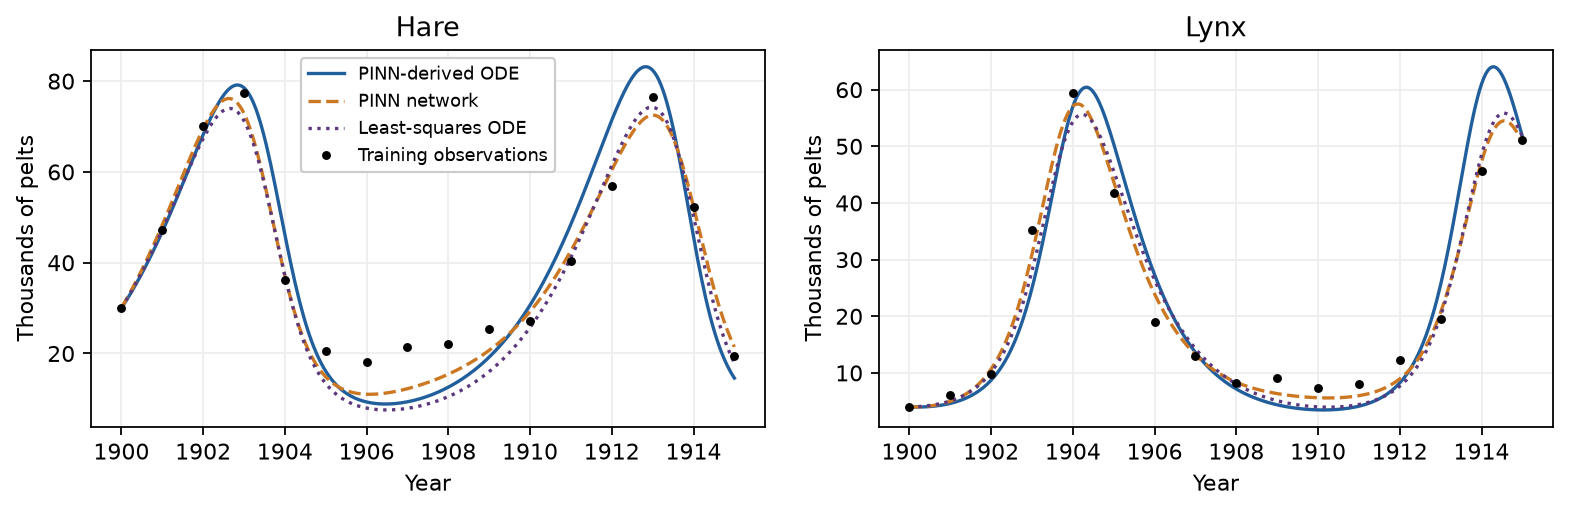

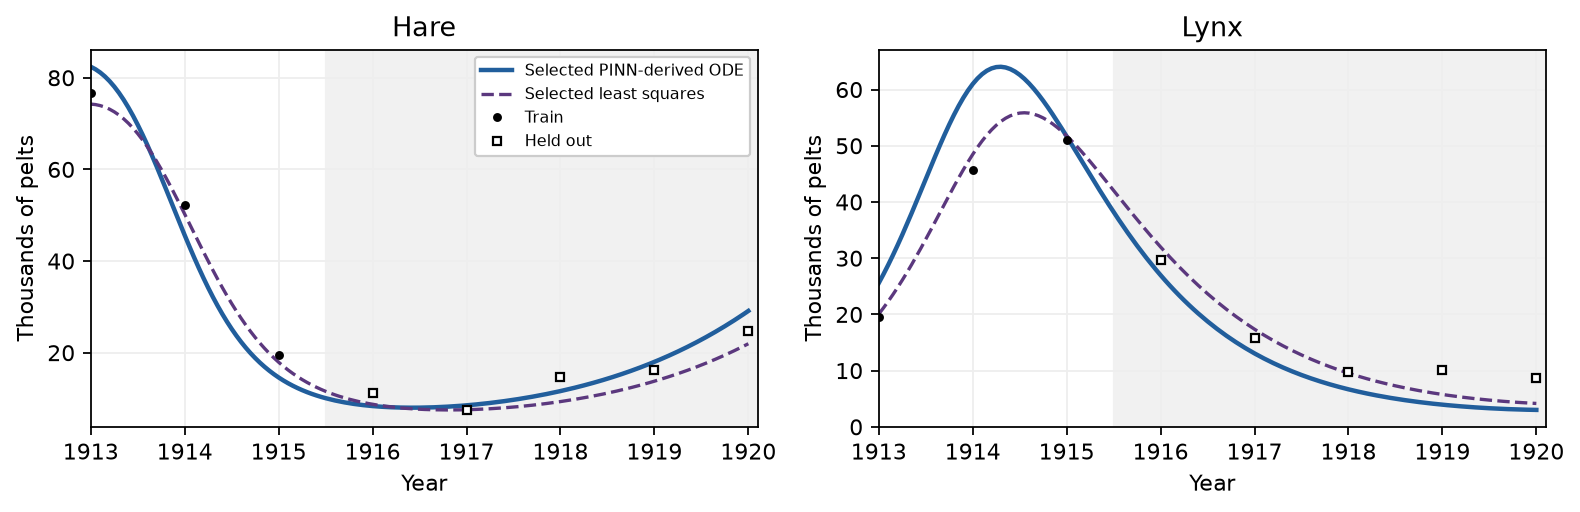

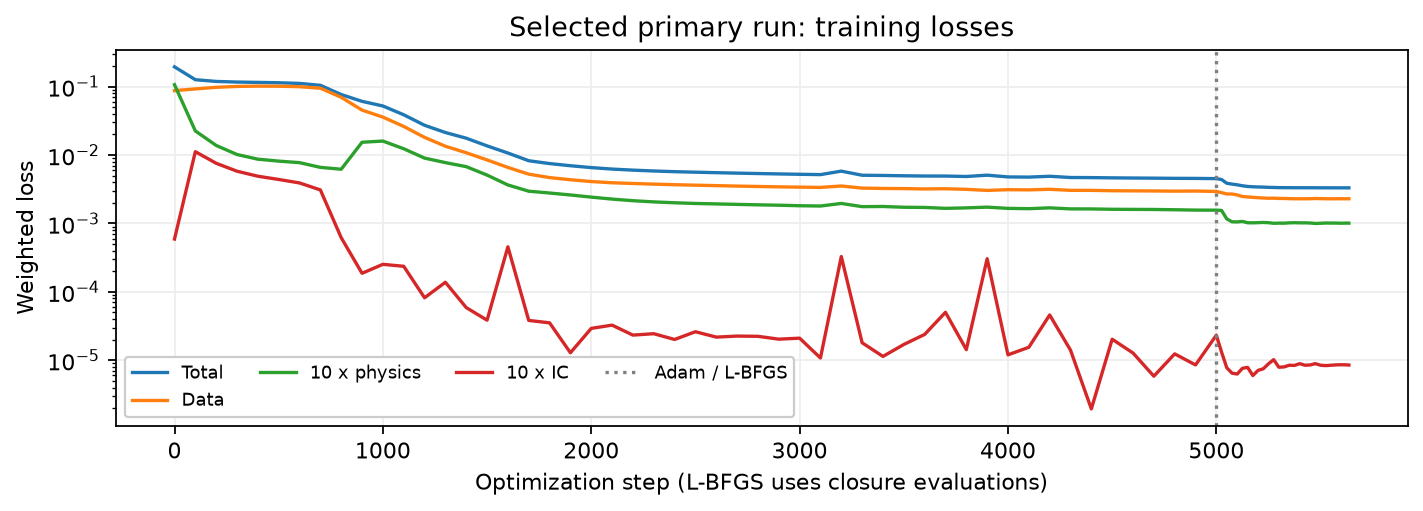

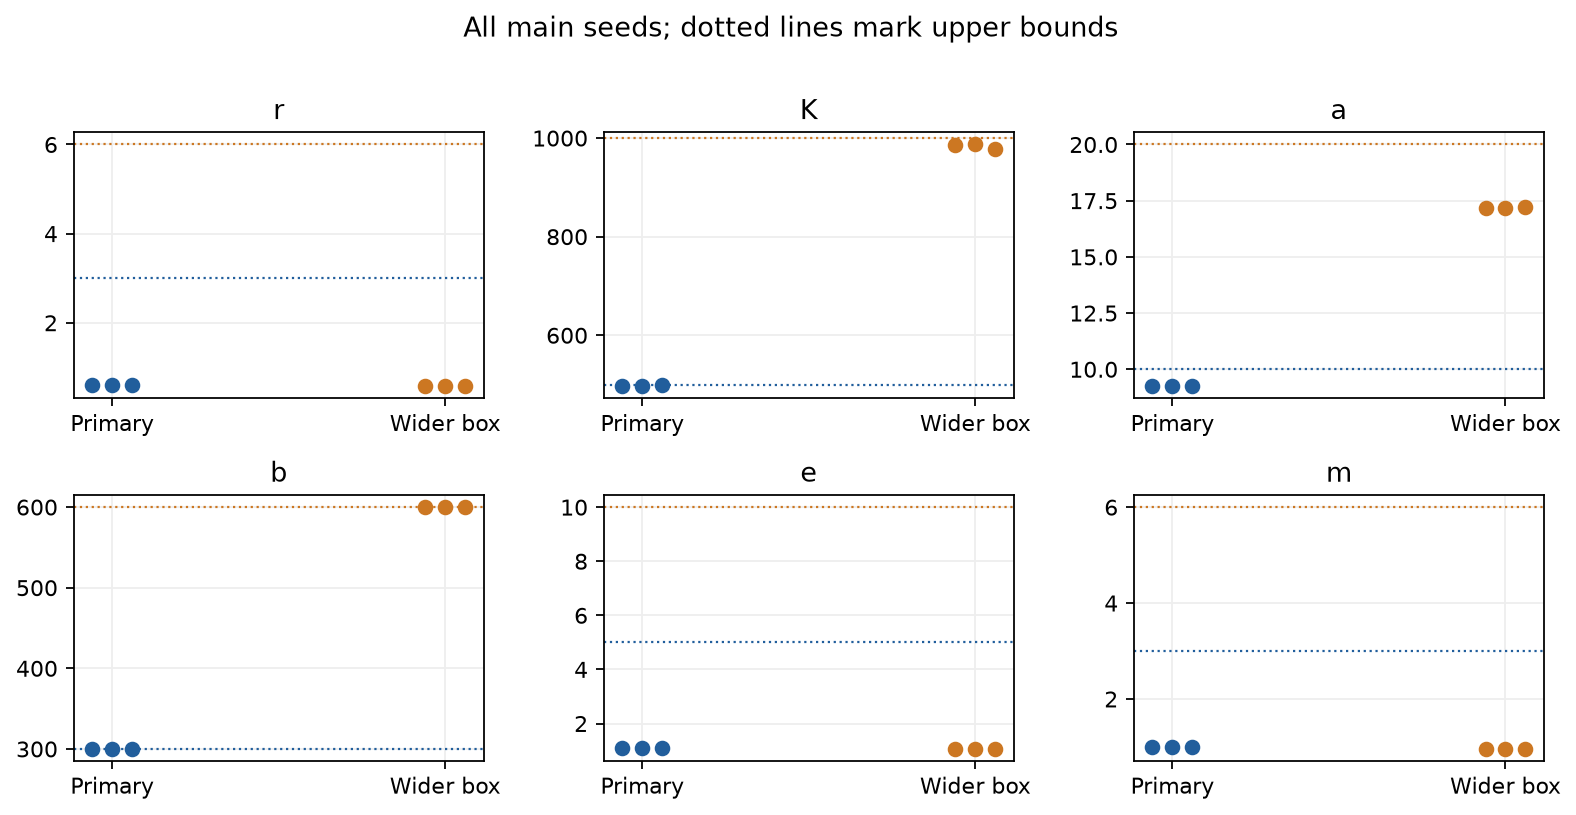

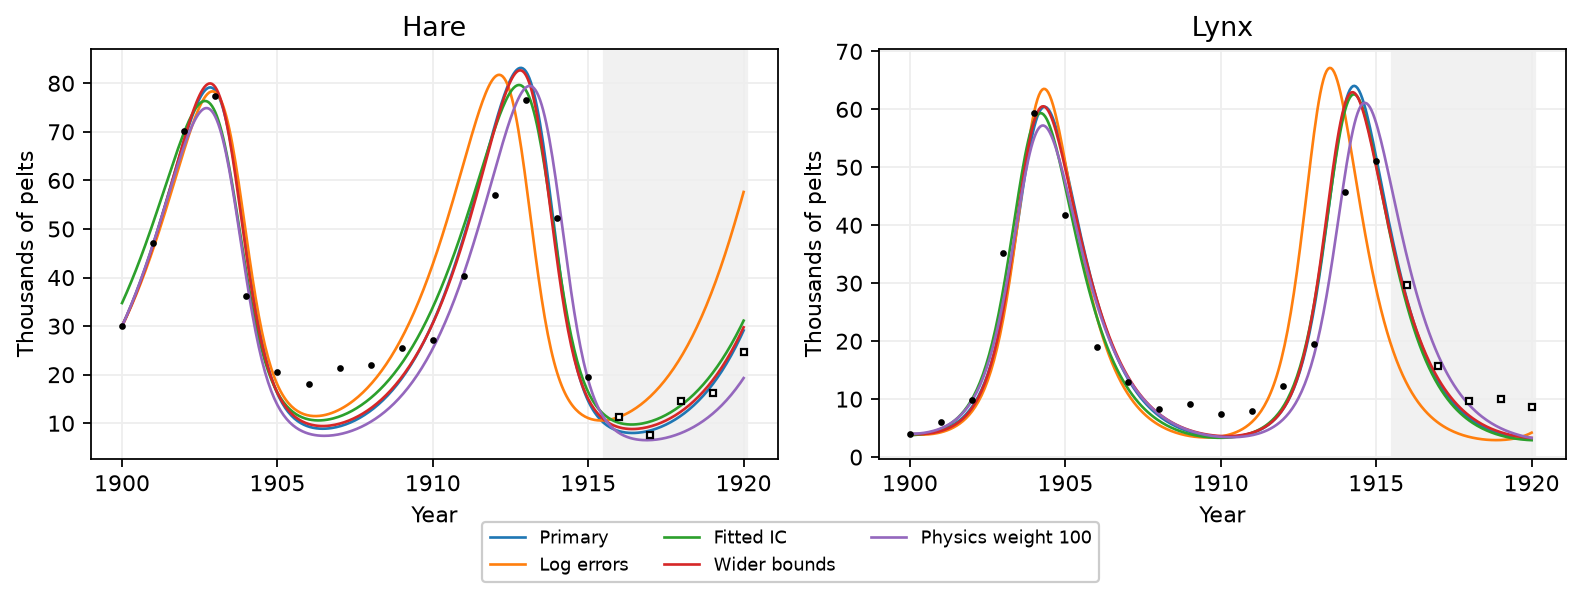

In [8]:
with (BASE/'yash_evaluation_v1/heldout_metrics.csv').open() as f:
    scores=list(csv.DictReader(f))
show_table([{k:r[k] for k in ['case','variant','hare_rmse','lynx_rmse','hare_mae','lynx_mae']} for r in scores if r['selected']=='True'])
receipt=json.loads((BASE/'yash_evaluation_v1/receipt.json').read_text())
assert receipt['test_used_for_model_choices'] is False
assert hashlib.sha256((BASE/'yash_evaluation_v1/heldout_metrics.csv').read_bytes()).hexdigest() == receipt['metrics_sha256']
for stem in ['fit','forecast','loss','bounds','sensitivity']:
    display(Image(filename=str(BASE/f'yash_evaluation_v1/figures/yash_historical_{stem}.png')))

## Batch reproduction
The source modules above contain the complete neural training algorithm. The runner saves each seed's
training history, parameters, initial states, ODE forecasts, network states, residuals and hashes. The
following commands deliberately use **new** directories. Match the runner/scorer directory constants
for a separate reproduction; never overwrite or retune the existing scored iteration.

```text
python scripts/run_historical_pinn.py --config configs/historical.json --output results/historical/reproduction_primary
python scripts/run_historical_pinn.py --config configs/historical_wider_bounds.json --output results/historical/reproduction_wide
python scripts/run_historical_pinn.py --config configs/historical_physics100.json --output results/historical/reproduction_physics100
python scripts/fit_historical_baseline.py --config configs/historical.json --output results/historical/reproduction_baseline
```

Full export, independent baseline, scoring and figure/report-building programs are in `scripts/` in
the same package. `docs/yash_historical_handoff.md` describes the team handoff and interpretation.
The complete dataset, original raw copies and provenance are under `data/historical/`.